In [6]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from datetime import datetime
import os
#from sklearn.ensemble import IsolationForest
#from sklearn.preprocessing import RobustScaler
#from sklearn.preprocessing import OneHotEncoder

In [7]:
#Lettura file dati mergiati ch4-bufale e robot, selezionando solo colonne che ci servono per questo momento.

#mandria_path = './dati_bufale/merged_buffalo_sniffer_AMS_detrended.csv'
mandria_path = './dati_bufale/dati_grezzi_agosto_luglio/Dataset_CH4/Bufale_Rinna/Luglio/luglio_merged_buffalo_sniffer_AMS_detrended.csv'

mandria = pd.read_csv(mandria_path)#, usecols = ['timestamp', 'CH4', 'CO2', 'Numero animale', 'milking_number', 'Ora inizio', 'Durata (mm:ss)', 'Milking_end', 'Produzione (kg)'])

mandria.head()

mandria['Numero animale'] = mandria['Numero animale'].apply(lambda x: int(x))
mandria['milking_number'] = mandria['milking_number'].apply(lambda x: int(x))


mandria_ch4 = mandria[['timestamp', 'CH4', 'Numero animale', 'milking_number']]

In [8]:
mandria.head()

,timestamp,CH4,CH4-mgm3,CO2,CO2-mgm3,date,time,Ora inizio,Numero animale,Azione,Durata (mm:ss),Produzione (kg),Numero mungitura,Durata (hh:mm:ss),Milking_end,milking_number
0,2024-07-01 09:54:00.472160,52.895661,125.893,628.9,1131.126,2024-07-01,09:54:00.472160,2024-07-01 09:54:00,5983,Mungitura,9.27,1.44,2.0,0 days 00:09:27,2024-07-01 10:03:27,1
1,2024-07-01 09:54:01.474686,42.995792,119.399,602.2,1083.965,2024-07-01,09:54:01.474686,2024-07-01 09:54:00,5983,Mungitura,9.27,1.44,2.0,0 days 00:09:27,2024-07-01 10:03:27,1
2,2024-07-01 09:54:02.476053,82.195922,145.115,562.5,1012.505,2024-07-01,09:54:02.476053,2024-07-01 09:54:00,5983,Mungitura,9.27,1.44,2.0,0 days 00:09:27,2024-07-01 10:03:27,1
3,2024-07-01 09:54:03.478415,79.396052,143.278,574.1,1033.385,2024-07-01,09:54:03.478415,2024-07-01 09:54:00,5983,Mungitura,9.27,1.44,2.0,0 days 00:09:27,2024-07-01 10:03:27,1
4,2024-07-01 09:54:04.481498,-14.903817,81.414,592.7,1066.325,2024-07-01,09:54:04.481498,2024-07-01 09:54:00,5983,Mungitura,9.27,1.44,2.0,0 days 00:09:27,2024-07-01 10:03:27,1


In [9]:
mandria_ch4.tail()

,timestamp,CH4,Numero animale,milking_number
890806,2024-07-23 12:42:31.873548,34.221017,233733,1740
890807,2024-07-23 12:42:32.875246,15.721147,233733,1740
890808,2024-07-23 12:45:00.238828,-13.759690,245591,1741
890809,2024-07-23 12:45:01.241485,-17.059559,245591,1741
890810,2024-07-23 12:45:02.244261,-18.459429,245591,1741


In [ ]:
mandria_ch4[1860:1865]

In [10]:
average_ch4 = np.mean(mandria_ch4['CH4'])
print("Average CH4 data:", average_ch4)
min_ch4 = mandria_ch4['CH4'].min()
print("Minimum CH4: ", min_ch4)
max_ch4 = mandria_ch4['CH4'].max()
print("Maximum CH4: ", max_ch4)

Average CH4 data: -1.7108921301493583
Minimum CH4:  -16022.976322403683
Maximum CH4:  15032.46148035486


<Figure size 432x288 with 0 Axes>

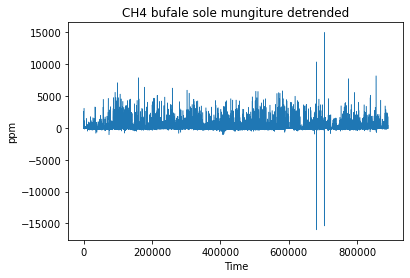

In [12]:
#Plot mandria solo mungiture di una settimana, post detrended.

plt.figure(facecolor='white')
plt.figure(facecolor='white')
plt.xlabel('Time')
plt.ylabel('ppm')
plt.title('CH4 bufale sole mungiture detrended')
plt.plot(mandria_ch4['CH4'], linewidth=0.5, label='CH4 bufale sole mungiture detrended')
plt.savefig("./dati_bufale/dati_grezzi_agosto_luglio/Dataset_CH4/Bufale_Rinna/Luglio/plot_bufale/CH4_bufale_sole_mungiture_detrended.png", format="png", dpi=200)

#dato interessante. Se selezionati i dati delle sole mungiture i dati negativi post detrended non ci sono più
#e il background non sembra altissimo.

In [13]:
#Calcolo media valori minimi per avere un'idea del dato "0"

ch4 = pd.DataFrame(mandria_ch4['CH4'])
minim = list()
minimum = ch4['CH4'].min()

for time in range(50):
    minimum = ch4['CH4'].min()
    minim.append(minimum)
    #index = ch4.index[ch4['CH4'] == minimum]
    #print(index)
    ch4 = ch4[ch4['CH4'] != minimum]

minim = pd.Series(minim)
print ("Average minimum is: ", minim.mean())

#Media dei minimi in un range customizzabile. Da una sorta di idea di background del dato generale.

Average minimum is:  -13693.227689870522


In [ ]:
#grouping data for animal and plotting all week individual animal

In [ ]:
######################################################

In [ ]:
#Altri tipi di test non ti servono, non scendere

In [ ]:
#Isolation forest on individual milking


animals = list(set(mandria_ch4['Numero animale']))
mungiture = list(set(mandria_ch4['milking_number']))
print(len(animals))
print(len(mungiture))
    
for mungitura in mungiture:
    milking_ch4 = mandria_ch4[mandria_ch4['milking_number'] == mungitura]
    milking_ch4 = milking_ch4.reset_index(drop=True)
    #print(milking_ch4.head())
    
    buffalo = milking_ch4.iloc[0,2]
    
    milking_model = pd.DataFrame(milking_ch4['CH4'])
    model = IsolationForest(n_estimators=100, warm_start=True)
    model.fit(milking_model)  # fit 10 trees  
    model.set_params(n_estimators=150)  # add 10 more trees  
    model.fit(milking_model)  # fit the added trees 
    model.get_params()
    
    milking_model['scores'] = model.decision_function(milking_model[['CH4']]) 
    milking_model['anomaly_score'] = model.predict(milking_model[['CH4']])    
    
    
    #Plot singoli animalei settimana
    plt.xlabel('Time')
    plt.ylabel('ppm')
    plt.title('CH4 isolation forest animale ' + str(buffalo))    
    not_anomalies = milking_model.loc[milking_model['anomaly_score'] == 1, 'CH4']
    plt.plot(not_anomalies)
    
    plt.show()
    #plt.savefig("./plot_bufale/animale")

In [ ]:
#######################################################################

In [ ]:
TODO: Test density distribution on milking data
        Remove outliers with 3-sigma method
        Scale?

In [ ]:
######################################################

In [ ]:
#Test normalization and then 3-sigma method
#if not normalization, try quartiles method

In [ ]:
mandria_ch4.head()
from sklearn import preprocessing

In [ ]:
#normalizing all the data and plot buffaloes and each milking
#mandria_normalized = preprocessing.normalize(mandria_normalized, axis=1)


# copy the data 
mandria_normalized = mandria_ch4.copy() 
  
# apply normalization techniques 
mandria_normalized['CH4'] = (mandria_normalized['CH4'] -
                           mandria_normalized['CH4'].mean()) / mandria_normalized['CH4'].std()     
  
# view normalized data    
print(mandria_ch4.head())
print(mandria_normalized.head())

average_ch4 = np.mean(mandria_ch4['CH4'])
print("Average CH4 data:", average_ch4)
min_ch4 = mandria_ch4['CH4'].min()
print("Minimum CH4: ", min_ch4)
max_ch4 = mandria_ch4['CH4'].max()
print("Maximum CH4: ", max_ch4)

average_ch4 = np.mean(mandria_normalized['CH4'])
print("Average CH4 data:", average_ch4)
min_ch4 = mandria_normalized['CH4'].min()
print("Minimum CH4: ", min_ch4)
max_ch4 = mandria_normalized['CH4'].max()
print("Maximum CH4: ", max_ch4)


plt.xlabel('Time')
plt.ylabel('ppm')
title = "CH4 mandria normalizzate"
plt.title(title)
plt.plot(mandria_normalized['CH4'], linewidth=0.5)



In [ ]:
#transform ch4 data on matrix data

In [ ]:
#try robust scaler to normalize the data

In [ ]:
#normalizing all the data and plot buffaloes and each milking
#mandria_normalized = preprocessing.normalize(mandria_normalized, axis=1)


# copy the data 
mandria_scaled = mandria_ch4.copy() 
mandria_scaled = np.array(mandria_scaled['CH4'])
print(mandria_scaled)
# apply normalization techniques 
mandria_scaled['CH4'] = RobustScaler(mandria_scaled)  
  
# view normalized data    
print(mandria_ch4.head())
print(mandria_normalized.head())

average_ch4 = np.mean(mandria_ch4['CH4'])
print("Average CH4 data:", average_ch4)
min_ch4 = mandria_ch4['CH4'].min()
print("Minimum CH4: ", min_ch4)
max_ch4 = mandria_ch4['CH4'].max()
print("Maximum CH4: ", max_ch4)

average_ch4 = np.mean(mandria_scaled['CH4'])
print("Average CH4 data:", average_ch4)
min_ch4 = mandria_scaled['CH4'].min()
print("Minimum CH4: ", min_ch4)
max_ch4 = mandria_scaled['CH4'].max()
print("Maximum CH4: ", max_ch4)


plt.xlabel('Time')
plt.ylabel('ppm')
title = "CH4 mandria normalizzate"
plt.title(title)
plt.plot(mandria_scaled['CH4'], linewidth=0.5)



In [ ]:
mandria_ch4.head()

In [ ]:
import seaborn as sns

In [ ]:
animals = list(set(mandria_ch4['Numero animale']))

for buffalo in animals[0:4]: #cut the square brackets to analyze for all 36 animals
    animal = mandria_ch4[mandria_ch4['Numero animale'] == buffalo]
    animal = animal.reset_index(drop=True)
    
    mungiture = set(animal['Numero mungitura'])
    #print(mungiture)
    
    for mungitura in mungiture:       
        milking_ch4 = animal[animal['Numero mungitura'] == mungitura]
        milking_ch4 = milking_ch4.reset_index(drop=True)

        
        ch4_milking = pd.DataFrame(milking_ch4['CH4'])
        copy = ch4_milking
        #print(ch4_milking.head())
        
        rs = RobustScaler()
        rs_data = rs.fit_transform(copy)
        rs_df = pd.DataFrame(rs_data)
        rs_df.columns = copy.columns
        #print(rs_df.head())
        
        mean = np.mean(rs_df)
        std = np.std(rs_df)
        print('mean of the dataset is', mean)
        print('std. deviation is', round(std, 2))
        
        threshold = round(std, 2)*3
        print('treshold is std x3: ', threshold)
        
        #if x > threshold x.drop
        
        series = pd.Series(rs_df['CH4'])
        
        #Plot singole mungiture settimana Robust Scaled
        plt.xlabel('Time')
        plt.ylabel('ppm robust scaled')
        title = "CH4 " + str(buffalo) + "-" + str(mungitura)
        plt.title(title)
        plt.plot(rs_df['CH4'], linewidth=0.5)
        #series.plot.kde()
        plt.show()
        
        #sns.kdeplot(array)#, hist=True, kde=True, bins=int(180/5), color = 'darkblue', hist_kws={'edgecolor':'black'},
             #kde_kws={'linewidth': 4})
        
        
        #sns.show()

In [ ]:
animals = list(set(mandria_ch4['Numero animale']))

for buffalo in animals[0:4]: #cut the square brackets to analyze for all 36 animals
    animal = mandria_ch4[mandria_ch4['Numero animale'] == buffalo]
    animal = animal.reset_index(drop=True)
    
    mungiture = set(animal['Numero mungitura'])
    #print(mungiture)
    
    for mungitura in mungiture:       
        milking_ch4 = animal[animal['Numero mungitura'] == mungitura]
        milking_ch4 = milking_ch4.reset_index(drop=True)

        
        ch4_milking = pd.DataFrame(milking_ch4['CH4'])
        copy = ch4_milking
        #print(ch4_milking.head())
        
        rs = RobustScaler()
        rs_data = rs.fit_transform(copy)
        rs_df = pd.DataFrame(rs_data)
        rs_df.columns = copy.columns
        #print(rs_df.head())
        
        mean = np.mean(rs_df)
        std = np.std(rs_df)
        print('mean of the dataset is', mean)
        print('std. deviation is', round(std, 2))
        
        threshold = round(std, 2)*3
        print('treshold is std x3: ', threshold)
        
        #if x > threshold x.drop
        
        series = pd.Series(rs_df['CH4'])
        
        #Plot singole mungiture settimana Robust Scaled
        plt.xlabel('Time')
        plt.ylabel('ppm robust scaled')
        title = "CH4 " + str(buffalo) + "-" + str(mungitura)
        plt.title(title)
        #plt.hist(rs_df['CH4'], linewidth=0.5)
        series.plot.kde()
        plt.show()
        
        #sns.kdeplot(array)#, hist=True, kde=True, bins=int(180/5), color = 'darkblue', hist_kws={'edgecolor':'black'},
             #kde_kws={'linewidth': 4})
        
        
        #sns.show()